In [1]:
import simsopt.configs.zoo as zoo
import numpy as np
import matplotlib.pyplot as plt
from simsopt.geo import CurveXYZFourier
from simsopt.field import Current, Coil, BiotSavart, coils_via_symmetries
coils, currents, ma = zoo.get_w7x_data()

/var/folders/jc/b9r1lwld74jfg3kzdjjk6_gc0000gn/T/ipykernel_73782/80311645.py:6: DeprecationWarning: get_w7x_data is deprecated and will be removed in the next major release; please use get_data('w7x', coil_order=..., magnetic_axis_order=..., points_per_period=...) instead.
  coils, currents, ma = zoo.get_w7x_data()


### Calculating B field at set of points


In [2]:
field = BiotSavart(coils_via_symmetries(coils, currents, nfp = 5, stellsym = True))
test_points = np.array([[0.5, 0.5, 0.1], [0.1, 0.1, -0.3]])
field.set_points(test_points)
print(field.B())

[[-4.45842904e-05  3.18847545e-05 -3.33056649e-03]
 [ 2.49651437e-05  2.50914179e-05 -3.05308091e-03]]


### Plotting 3D Coil Geometry in XYZ 

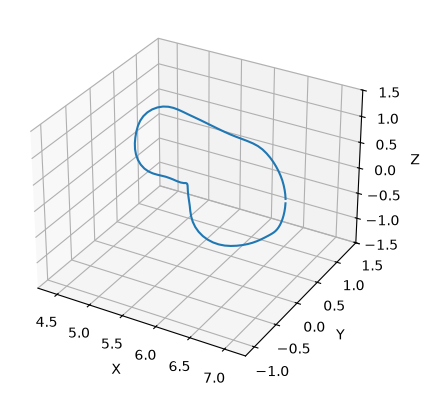

In [3]:
curve = coils[0]
xyz = curve.gamma() # want to perturb each xyz coordiante with GP in 3D
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
plt.plot(xyz[:,0], xyz[:,1],xyz[:,2])
ax.set(xlim=(4.2,7.3),
       ylim= (-1.2,1.5),
       zlim= (-1.5,1.5),
       xlabel='X',
       ylabel='Y',
       zlabel='Z')
plt.show()

### Defining Gaussian Process-Based Coil Perturbations


The magnetic coil is represented as $\gamma(s) = \gamma_0(s) + \delta \gamma(s)$, where $\gamma_0(s)$ is the optimized coil from SIMSOPT. The values of *s* are given by the quadrature points on the interval (0,1) ($\texttt{curve.quadpoints}$)

We define the Gaussian Process $\delta \gamma(s) = \textbf{GP}(0, k)$, where *k* is the covariance/kernel function.

Since we have periodic *s*-parametrization ($\gamma(s+2\pi) = \gamma(s)$) , the kernel is a periodic squared exponential function.

$$
k(s,s') = k(d) =  \sigma^2\sum_{n \in \textbf{Z}}\exp{(-\tfrac{(d + n2\pi)^2}{2l^2})}, \text{ with } d = \|\mathbf{s - s'}\|_2
$$
The KL expansion says that we can express a centered (zero-mean) GP as an infinite sum of orthogonal functions weighted by uncorrelated random variables. 
$$
\delta\gamma(s) = \sum_{n \in \textbf{Z}}\sqrt{\lambda_n}\xi_n e_n(s), \text{ with } \xi_i = \mathcal{Z}_3(0,1)
$$ 
In the special case that our kernel function is periodic, the natural choice for an orthogonal basis are *sin(ns)* and *cos(ns)*. This has the additional benefit of perfectly matching up with the Fourier basis of the coil parametrization provided by SIMSOPT. Furthermore, the kernel eigenvalues $\lambda_n$ are extremeley easy to find analytically:

$$
\lambda_n = S_n = \tfrac{1}{2\pi}\int_0^{2\pi}k(u)e^{-inu}du = \tfrac{\sigma^2 l}{\sqrt{2\pi}}\exp{(-\tfrac{l^2n^2}{2})}
$$
Thus, the KL expansion of the coil perturbation is expressed as follows:
$$
\delta\gamma(s) = \sum_{n ≥ 0}^N\sigma\sqrt{\tfrac{2l}{\sqrt{2\pi}}}\exp{(-\tfrac{l^2n^2}{4})}(\xi_n^c\cos(2\pi ns) + \xi_n^s\sin(2\pi ns))
$$
We can choose to truncate *N* for a specific number of terms, but regardless, it is bounded above by the order of the SIMSOPT Fourier basis of the optimized coil ($\texttt{curve.order}$). 

Note: the $2\pi ns$ angle for *sin* and *cos* comes from the fact that *s* is only between (0,1), so a factor of $2\pi$ is needed such that the coil closes at $2\pi$ radians. A factor of $\sqrt{2}$ is included in the coefficients to adjust for the positive and negative frequency spectrum in the kernel's Fourier series.


In [4]:
def gp_perturbation_analytic(curve, sigma, length_scale, n_terms=None, rng=None):
    """
    Zero-mean GP perturbation of 3D points parametrized by t.

    t            : (N,) parameter values (for simsopt curves, curve.quadpoints in [0, 1))
    sigma        : standard deviation of the perturbation (meters)
    length_scale : SE length scale, in the same units as t
    n_terms      : number of KL modes kept (None = all N)
    periodic     : wrap the kernel with period 1 so closed curves stay closed
    Returns delta of shape (N, 3); x, y, z are independent GPs with the same kernel.
    """
    rng = np.random.default_rng(rng) ## FIX RNG FOR REPRODUCIBILITY! 
    t = np.asarray(curve.quadpoints, dtype=float)
    N = len(t) # number of points
    n_terms = n_terms if n_terms is not None else curve.order
    d = t[:, None] - t[None, :]
    k = np.arange(1,n_terms+1) # (n,)

    S_n = sigma**2 * length_scale * 1/np.sqrt(2 * np.pi) * np.exp(-0.5 * (length_scale *k)**2) # (n,)
    c0 = sigma**2 * length_scale * 1/np.sqrt(2 * np.pi) * rng.standard_normal(3) # (3,)
    a = np.sqrt(2*S_n)[:, None] * rng.standard_normal((n_terms, 3))  # (n,3) independent weights per coordinate
    b = np.sqrt(2*S_n)[:, None] * rng.standard_normal((n_terms, 3))  # (n,3) independent weights per coordinate

    def delta(t):
        ang = 2*np.pi*np.multiply.outer(np.asarray(t, float), k) # (N,n)
        return c0 + np.cos(ang) @ a + np.sin(ang) @ b # (N,3)

    return delta(t), (c0, a, b), S_n # returns perturbtions, the KL, and kernel spectral density

 #### GP KL expansion-based method if periodicity was not assumed

In this case, we numerically solve the eigenvalue equation for *k*

In [ ]:
def gp_perturbation(t, sigma, length_scale, n_terms=None, periodic=True, rng=None):
    """
    Zero-mean GP perturbation of 3D points parametrized by t.

    t            : (N,) parameter values (for simsopt curves, curve.quadpoints in [0, 1))
    sigma        : standard deviation of the perturbation (meters)
    length_scale : SE length scale, in the same units as t
    n_terms      : number of KL modes kept (None = all N)
    periodic     : wrap the kernel with period 1 so closed curves stay closed
    Returns delta of shape (N, 3); x, y, z are independent GPs with the same kernel.
    """
    rng = np.random.default_rng(rng)
    t = np.asarray(t, dtype=float)
    N = len(t)
    d = t[:, None] - t[None, :]

    if periodic:
        # Sum of SE kernels over periodic images: still positive semi-definite
        K = sum(np.exp(-0.5 * ((d + m) / length_scale) ** 2) for m in range(-3, 4))
    else:
        K = np.exp(-0.5 * (d / length_scale) ** 2)
    K = sigma**2 * K

    w, V = np.linalg.eigh(K)
    idx = np.argsort(w)[::-1]
    w, V = np.clip(w[idx], 0, None), V[:, idx]

    n = N if n_terms is None else min(n_terms, N)
    z = rng.standard_normal((n, 3))                 # independent weights per coordinate
    return V[:, :n] @ (np.sqrt(w[:n])[:, None] * z)  # (N, 3), zero mean

### Plotting perturbations alongside optimal coil

Can play around with values of $\sigma, l, \text{and } n_{\text{terms}}$ to see how perturbations change.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider
from simsopt.geo import CurveXYZFourier
from simsopt.field import Coil, BiotSavart, Current

curve = coils[0]
xyz = curve.gamma()

current = currents[0].current            
test_points = np.array([[0.5, 0.5, 0.1], [0.1, 0.1, -0.3]])
test_points = np.ascontiguousarray(test_points, dtype=np.float64)

# Unperturbed field, computed once
field = BiotSavart([Coil(curve, Current(current))])
field.set_points(test_points)
B_old = field.B().copy()

def plot(sigma=0.02, length_scale=0.1, n_terms=10):
    delta, _, _ = gp_perturbation_analytic(curve, sigma, length_scale, n_terms, rng=42)
    xyz_pert = xyz + delta

    # Fit perturbed points to a Fourier curve and compute the new field
    c = CurveXYZFourier(curve.quadpoints, order=curve.order)
    c.least_squares_fit(xyz_pert)
    field_new = BiotSavart([Coil(c, Current(current))])
    field_new.set_points(test_points)
    B_new = field_new.B()

    fit_err = np.abs(c.gamma() - xyz_pert).max()

    fig = plt.figure(figsize=(13, 6))
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    ax.plot(*xyz.T, label="opt")
    ax.plot(*xyz_pert.T, label="perturbed")
    ax.set(xlim=(4.2, 7.3), ylim=(-1.2, 1.5), zlim=(-1.5, 1.5))
    ax.legend()

    # Text panel with the field values
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.axis("off")
    lines = []
    for i, p in enumerate(test_points):
        dB = B_new[i] - B_old[i]
        lines += [
            f"point {i}: {np.round(p, 3)}",
            f"  old B  = {np.array2string(B_old[i], precision=4)} T",
            f"  new B  = {np.array2string(B_new[i], precision=4)} T",
            f"  dB     = {np.array2string(dB, precision=2)} T",
            f"  |dB|/|B| = {np.linalg.norm(dB)/np.linalg.norm(B_old[i]):.2e}",
            "",
        ]
    ax2.text(0, 1, "\n".join(lines), va="top", family="monospace", fontsize=9)
    plt.show()

interact(
    plot,
    sigma=FloatSlider(min=0.0, max=0.3, step=0.005, value=0.02,
                      description="sigma (m)", continuous_update=False),
    length_scale=FloatSlider(min=0.01, max=1, step=0.01, value=0.1,
                             description="length l", continuous_update=False),
    n_terms=IntSlider(min=1, max=curve.order, value=min(10, curve.order),
                      description="n terms", continuous_update=False)
);

interactive(children=(FloatSlider(value=0.02, continuous_update=False, description='sigma (m)', max=0.3, step=…

In [ ]:
from ipywidgets import interact, FloatSlider, IntSlider

def plot(sigma=0.02, length_scale=0.1, n_terms=10):
    delta, _,_ = gp_perturbation_analytic(curve, sigma, length_scale, n_terms, rng= 42)
    xyz_pert = xyz + delta

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(projection="3d")
    ax.plot(*xyz.T, label="opt")
    ax.plot(*xyz_pert.T, label="perturbed")
    ax.set(xlim=(4.2, 7.3), ylim=(-1.2, 1.5), zlim=(-1.5, 1.5), xlabel="X", ylabel="Y", zlabel="Z")
    ax.legend()
    plt.show()

interact(
    plot,
    sigma=FloatSlider(min=0.0, max=0.2, step=0.005, value=0.02,
                      description="sigma (m)", continuous_update=False),
    length_scale=FloatSlider(min=0.01, max=0.5, step=0.01, value=0.1,
                             description="length ℓ", continuous_update=False),
    n_terms=IntSlider(min=1, max=curve.order, value=min(10, curve.order),
                      description="n terms", continuous_update=False)
);

interactive(children=(FloatSlider(value=0.02, continuous_update=False, description='sigma (m)', max=0.2, step=…

### Recalculate B field at set of points

Refitting method may need some tweaks. Potential issues if the perturbation order isnt the same as the optimized coil order.

In [59]:
current= currents[0].current # current for the first coil
c = CurveXYZFourier(curve.quadpoints, order = curve.order) # create a new curve object to hold the perturbed points
c.least_squares_fit(xyz_pert) # fit the perturbed points to the new curve object
coil_pert = Coil(c, Current(current)) 

field_new = BiotSavart([coil_pert]) 
field_new.set_points(test_points) # calculate new B field at same set of points as before
print("old B field:", field.B())
print("new B field:", field_new.B())
print("percentage change in B field:", 100*np.abs(field_new.B() - field.B())/field.B())


old B field: [[-4.45842904e-05  3.18847545e-05 -3.33056649e-03]
 [ 2.49651437e-05  2.50914179e-05 -3.05308091e-03]]
new B field: [[ 0.00102415  0.00435248  0.00112274]
 [-0.00015212  0.0035213   0.00089472]]
percentage change in B field: [[-2397.1000547  13550.65228151  -133.71012308]
 [  709.33849602 13933.89812982  -129.30552074]]
